# 03 — The Hand Stays Hot? Strokes-gained momentum in D3 men's golf (poster notebook)

**What this notebook is.** The analysis behind the poster *"The Hand Stays Hot: Momentum Beyond
Skill in College Golf"*, built on the clean data from `01_cleaning.ipynb`. It is laid out in the
same order as the poster, so each section fills one box:

| poster box | section | what comes out |
|---|---|---|
| Introduction | 1 | draft text |
| Data | 2 | a "data at a glance" table and paste-ready text |
| Methods | 3 | the method in four steps and Figure M1 (one round of strokes gained) |
| Analysis & Results | 4 | Figures R1–R3, the headline table and the sensitivity table |
| Conclusion / Future / Sources | 5–7 | paste-ready text |
| (abstract) | 8 | a revised abstract whose numbers are printed from the results |

Every figure is written to `poster/figures/` as a 300-dpi PNG and a vector PDF. Every cell
marked **POSTER TEXT** prints text whose numbers come from this run, so nothing on the poster is
typed by hand.

**How this differs from the earlier strokes-gained notebook (`archive/college_golf.ipynb`).**
That notebook produced the abstract's numbers, and had five gaps that this one closes:

1. **Field definition.** It keyed the field on `(tournament, round, hole_number)`. In two-course
   events that averages hole 5 of course A with hole 5 of course B. The field here is
   `(tournament, round, layout_id)` from the cleaning notebook.
2. **Cleaning.** It used only per-hole checks. `01_cleaning` also removes duplicate and copied
   cards, half-cards filled in from a total, fabricated events and wrong pars. Those errors are
   exactly the ones that manufacture streaks.
3. **Order of play.** It counted 9→10 as consecutive holes. Under a 10th-tee start, hole 9 is
   the player's *last* hole and hole 10 their *first*. Only within-nine pairs are used here.
4. **Day form.** A season baseline removes *who the player is*, not *how they are playing today*.
   Back-to-back holes correlate partly because both belong to the same good or bad day. This is
   the biggest gap, and section 4 tests it directly by shuffling hole order inside each nine.
5. **Inference.** p-values assumed independent holes. Here, confidence intervals come from a
   bootstrap over players, and the momentum test is a permutation test.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT       = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
HOLES_PATH = ROOT / "data" / "clean" / "d3_clean_holes.parquet"
FIG_DIR    = ROOT / "poster" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIELD_KEYS = ["tournament_id", "round_number", "layout_id"]   # same holes, same day (01_cleaning)
N_HOLES    = 18

# ---- primary specification (fixed before looking at results; alternatives in section 4e) ----
GENDER             = "Men"
LEVEL              = "TOURNAMENT"   # team qualifiers excluded
EXCLUDE_MATCH_NAME = True           # duals / tri-matches: format may be match play
MIN_FIELD          = 10             # players on the course that day
MIN_OTHER_ROUNDS   = 3              # season baseline needs 3+ OTHER rounds (54+ holes) that season
MAX_LAG            = 8              # longest gap that stays inside one nine

# ---- inference ----
N_BOOT = 1000                       # bootstrap over players
N_PERM = 500                        # shuffles of hole order within each nine
SEED   = 2026
rng    = np.random.default_rng(SEED)

# ---- poster style (red matches the poster headers; palette validated for colour-blind separation) ----
RED, BLUE = "#B22A36", "#2F6DB5"
INK, MUTED, GRID, NULL_FILL = "#1a1a1a", "#6b6b6b", "#e4e4e4", "#cfcfcf"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 13, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 13, "axes.labelcolor": INK, "axes.edgecolor": "#9a9a9a",
    "xtick.labelsize": 12, "ytick.labelsize": 12, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 12, "lines.linewidth": 2, "figure.dpi": 100,
})

def save(fig, name):
    "Write a poster figure as 300-dpi PNG and vector PDF."
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    print(f"saved poster/figures/{name}.png and .pdf")

TESTS = []
def check(name, passed, detail=""):
    "Record a test. A failure stops the notebook."
    passed = bool(passed)
    TESTS.append({"test": name, "passed": passed, "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
    assert passed, f"TEST FAILED: {name}  {detail}"

pd.set_option("display.width", 200, "display.max_columns", 30)

## 1. Introduction  *(poster box: Introduction)*

**POSTER TEXT (draft).**

> Do athletes get "hot"? Gilovich, Vallone & Tversky (1985) found no hot hand in basketball
> shooting, and for 30 years it was called a cognitive illusion. Miller & Sanjurjo (2018) then
> showed that the original test was biased against finding streaks, and the debate reopened.
> Golf is a cleaner test than basketball: no defender adjusts and no one chooses harder shots
> after a make. On the PGA Tour, Elmore & Urbaczewski (2018) found no hot hand but a
> significant *cold* hand. **Does momentum exist in college golf, once we account for who the
> player is and what kind of day they are having?**

The question has three layers, and the poster answers each one in turn:

1. Does beating the field on one hole predict beating it on the next? (raw carry-over)
2. Is that just skill, because good players beat the field on every hole? (season baseline)
3. Is it just *day form*, because a player having a good day is good on every hole that day?
   (hole order shuffled within a nine)

Only what survives layer 3 is momentum in the hot-hand sense.

## 2. Data  *(poster box: Data)*

Source: hole-by-hole scores for NCAA Division III golf, 2023-24 to 2025-26, cleaned by
`01_cleaning.ipynb` (60 tests, every dropped round has a recorded reason).

**Strokes gained is computed on the whole clean field, before the scope filter.** The field is
everyone who played those holes that day, whether or not they end up in the analysis sample.

$$\text{SG}_{ih} = \underbrace{\frac{1}{n_h - 1}\sum_{j \ne i} \text{score}_{jh}}_{\text{rest of the field on that hole, that day}} - \text{score}_{ih}$$

Positive SG means the player beat the field. Leaving the player out of their own benchmark
matters with college field sizes. In a 12-player field, a player's own bogey would otherwise
make the hole look 1/12 of a stroke harder and partly explain itself.

In [2]:
holes = pd.read_parquet(HOLES_PATH)
check("hole table is whole rounds, holes 1..18 in order",
      len(holes) % N_HOLES == 0
      and (holes["hole_number"].to_numpy().reshape(-1, N_HOLES) == np.arange(1, N_HOLES + 1)).all())

g = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False, observed=True)["score"]
tot, n = g.transform("sum"), g.transform("size")
holes["field_avg"] = (tot - holes["score"]) / (n - 1)
holes["sg"] = holes["field_avg"] - holes["score"]

check("one par per hole within a field (no two courses pooled)",
      (holes.groupby(FIELD_KEYS + ["hole_number"], observed=True)["par"].nunique() == 1).all())
check("leave-one-out SG sums to exactly zero over every field-hole",
      np.abs(holes.groupby(FIELD_KEYS + ["hole_number"], observed=True)["sg"].sum()).max() < 1e-9)

# one row per round, and the rounds x 18 SG matrix for the whole clean file
R_ALL  = holes.iloc[::N_HOLES][["round_id", "tournament_id", "round_number", "layout_id", "season_id", "season_label",
                                "school_id", "player_id", "team_gender", "tournament_level", "field_size",
                                "is_match_name", "is_extreme_round"]].reset_index(drop=True)
R_ALL["team_gender"] = R_ALL["team_gender"].astype(str)
SG_ALL = holes["sg"].to_numpy().reshape(-1, N_HOLES)
SCORE_ALL = holes["score"].to_numpy().reshape(-1, N_HOLES)
FAVG_ALL  = holes["field_avg"].to_numpy().reshape(-1, N_HOLES)
PAR_ALL   = holes["par"].to_numpy().reshape(-1, N_HOLES)
print(f"{len(R_ALL):,} clean rounds, all genders and levels")

[PASS] hole table is whole rounds, holes 1..18 in order
[PASS] one par per hole within a field (no two courses pooled)


[PASS] leave-one-out SG sums to exactly zero over every field-hole
165,173 clean rounds, all genders and levels


In [3]:
def scope_mask(gender=GENDER, level=LEVEL, exclude_match=EXCLUDE_MATCH_NAME, min_field=MIN_FIELD,
               exclude_extreme=False, season=None):
    "Boolean mask over R_ALL for one analysis scope."
    m = (R_ALL["team_gender"] == gender) & (R_ALL["tournament_level"] == level) & (R_ALL["field_size"] >= min_field)
    if exclude_match:
        m &= ~R_ALL["is_match_name"]
    if exclude_extreme:
        m &= ~R_ALL["is_extreme_round"]
    if season is not None:
        m &= R_ALL["season_label"].astype(str) == season
    return m.to_numpy()


def build(mask, min_other=MIN_OTHER_ROUNDS):
    """Season baseline for every round in `mask`, from the player's OTHER rounds that season.

    Leaving the whole round out (not just the two holes being compared) keeps the baseline free
    of anything that happened that day. Returns the rounds that have a trusted baseline, with
    raw SG, SG minus the season mean (D), and SG standardised by the season mean and SD (Z).
    """
    Rs, M = R_ALL[mask].reset_index(drop=True), SG_ALL[mask]
    key = Rs.groupby(["player_id", "season_id"]).ngroup().to_numpy()
    rs, rss = M.sum(1), (M ** 2).sum(1)
    cnt, s1, s2 = np.bincount(key), np.bincount(key, rs), np.bincount(key, rss)
    other = cnt[key] - 1
    ok = other >= min_other
    nh = np.where(ok, other * N_HOLES, np.nan)
    mu = (s1[key] - rs) / nh
    sd = np.sqrt(((s2[key] - rss) - nh * mu ** 2) / (nh - 1))
    ok &= sd > 0
    mu, sd = mu[:, None], sd[:, None]
    return {"R": Rs[ok].reset_index(drop=True), "SG": M[ok], "D": (M - mu)[ok], "Z": ((M - mu) / sd)[ok],
            "mask_rows": np.flatnonzero(mask)[ok], "n_scope": int(mask.sum())}


PRIMARY = build(scope_mask())
R, SG, D, Z = PRIMARY["R"], PRIMARY["SG"], PRIMARY["D"], PRIMARY["Z"]

check("every round in the sample has 18 finite z-scores", np.isfinite(Z).all())
check("standardised holes average about zero (baseline is centred)",
      np.allclose(Z.mean(), 0, atol=0.02), f"mean z {Z.mean():+.4f}")

[PASS] every round in the sample has 18 finite z-scores
[PASS] standardised holes average about zero (baseline is centred)  (mean z -0.0026)


In [4]:
# ---- attrition: how the clean file becomes the analysis sample ----
steps = [
    ("clean rounds (all D3 golf)",            np.ones(len(R_ALL), bool)),
    (f"{GENDER}'s golf",                       (R_ALL["team_gender"] == GENDER).to_numpy()),
    ("stroke-play tournaments (no qualifiers)", (R_ALL["tournament_level"] == LEVEL).to_numpy()),
    ("not a dual / tri-match event",           (~R_ALL["is_match_name"]).to_numpy()),
    (f"field of {MIN_FIELD}+ players on the course", (R_ALL["field_size"] >= MIN_FIELD).to_numpy()),
]
m, rows = np.ones(len(R_ALL), bool), []
for label, s in steps:
    m &= s
    rows.append({"step": label, "rounds": int(m.sum()), "players": R_ALL.loc[m, "player_id"].nunique(),
                 "tournaments": R_ALL.loc[m, "tournament_id"].nunique()})
rows.append({"step": f"player has {MIN_OTHER_ROUNDS}+ other rounds that season",
             "rounds": len(R), "players": R["player_id"].nunique(), "tournaments": R["tournament_id"].nunique()})
attrition = pd.DataFrame(rows).set_index("step")
print(attrition.to_string())
check("attrition ends at the analysis sample", attrition["rounds"].iloc[-1] == len(R))

                                         rounds  players  tournaments
step                                                                 
clean rounds (all D3 golf)               165173     8997         2665
Men's golf                               104649     5779         1526
stroke-play tournaments (no qualifiers)  102785     5766         1431
not a dual / tri-match event             100868     5711         1301
field of 10+ players on the course        98363     5698         1089
player has 3+ other rounds that season    94671     4662         1089
[PASS] attrition ends at the analysis sample


In [5]:
# ---- POSTER TEXT: Data box ----
PAIRS = {L: np.array([(h, h + L) for h in range(N_HOLES - L) if (h < 9) == (h + L < 9)]) for L in range(1, MAX_LAG + 1)}
n_pairs = len(R) * len(PAIRS[1])
glance = pd.Series({
    "seasons": f"{R['season_label'].astype(str).min()} to {R['season_label'].astype(str).max()}",
    "tournaments": f"{R['tournament_id'].nunique():,}",
    "schools": f"{R['school_id'].nunique():,}",
    "players": f"{R['player_id'].nunique():,}",
    "player-rounds": f"{len(R):,}",
    "holes": f"{len(R) * N_HOLES:,}",
    "back-to-back hole pairs": f"{n_pairs:,}",
    "median field size": f"{int(R['field_size'].median())} players",
}, name="Data at a glance")
DATA_AT_A_GLANCE = glance
print(glance.to_string(), "\n")

dropped_pct = 100 * (1 - len(holes) / N_HOLES / pd.read_parquet(ROOT / "data" / "clean" / "d3_round_audit.parquet",
                                                                columns=["status"]).shape[0])
print("POSTER TEXT -----------------------------------------------------------------")
print(f"""Hole-by-hole scores from every NCAA Division III men's stroke-play tournament,
{glance['seasons']}, supplied by Clippd: {glance['player-rounds']} rounds by {glance['players']} players
from {glance['schools']} schools in {glance['tournaments']} tournaments. A tested cleaning pipeline removed
{dropped_pct:.1f}% of raw rounds (duplicated or copied cards, nine-hole totals spread across holes,
wrong course pars, fabricated events), each with a recorded reason. Rounds are kept or dropped
whole, so every round is a complete 18-hole sequence. The unit of analysis is a pair of
back-to-back holes in the same nine: {glance['back-to-back hole pairs']} pairs.""")

seasons                    2023-24 to 2025-26
tournaments                             1,089
schools                                   297
players                                 4,662
player-rounds                          94,671
holes                               1,704,078
back-to-back hole pairs             1,514,736
median field size                  60 players 

POSTER TEXT -----------------------------------------------------------------
Hole-by-hole scores from every NCAA Division III men's stroke-play tournament,
2023-24 to 2025-26, supplied by Clippd: 94,671 rounds by 4,662 players
from 297 schools in 1,089 tournaments. A tested cleaning pipeline removed
2.0% of raw rounds (duplicated or copied cards, nine-hole totals spread across holes,
wrong course pars, fabricated events), each with a recorded reason. Rounds are kept or dropped
whole, so every round is a complete 18-hole sequence. The unit of analysis is a pair of
back-to-back holes in the same nine: 1,514,736 pairs.


## 3. Methods  *(poster box: Methods)*

**POSTER TEXT (four steps).**

1. **Strokes gained per hole.** The player's score against the average of everyone else who
   played that hole, on that course, that day (leave-one-out). This removes hole difficulty,
   weather and pin positions.
2. **Remove skill and streakiness.** Standardise each hole by the player's own season:
   $z = (\text{SG} - \bar{\text{SG}}_{\text{season}}) / s_{\text{season}}$, where the mean and SD come
   from the player's *other* rounds that season. A z of +1 means one of that player's own
   standard deviations better than usual.
3. **Carry-over.** Correlate z on hole *h* with z on hole *h + 1*, using only pairs inside the
   same nine. With no tee-time data, 9→10 and 18→1 may not be consecutive in play (10th-tee
   and shotgun starts).
4. **Separate momentum from day form.** Shuffle the order of holes within each nine, 500 times.
   Shuffling keeps each player's good or bad day intact but breaks any hole-to-hole sequence.
   **Momentum = observed carry-over − shuffled carry-over.** Confidence intervals come from
   resampling whole players (1,000 bootstrap draws), since a player's holes are not independent.

A second check on step 4: if the carry-over were only day form, holes 1 apart and holes 6 apart
in the same nine would correlate equally. Momentum shows up as a **lag-1 spike** (Figure R2).

In [6]:
# ---- Machinery: every correlation is computed from per-round sums, so bootstraps over players are cheap ----
def corr_from(s):
    "Pearson r from stacked sums [n, Sa, Sb, Saa, Sbb, Sab] (last axis)."
    n, sa, sb, saa, sbb, sab = np.moveaxis(np.asarray(s, float), -1, 0)
    return (sab - sa * sb / n) / np.sqrt((saa - sa ** 2 / n) * (sbb - sb ** 2 / n))


def lag_sums(M, lag):
    "Per-round sums for the within-nine pairs (h, h+lag)."
    a, b = M[:, PAIRS[lag][:, 0]], M[:, PAIRS[lag][:, 1]]
    return np.stack([np.full(len(M), a.shape[1], float), a.sum(1), b.sum(1),
                     (a * a).sum(1), (b * b).sum(1), (a * b).sum(1)], 1)


def lag_profile(M, lags=range(1, MAX_LAG + 1)):
    return np.array([corr_from(lag_sums(M, L).sum(0)) for L in lags])


def shuffle_within_nines(M, rng):
    "Random order of the holes inside each nine of each round (day form kept, sequence broken)."
    out = M.copy()
    for s in (slice(0, 9), slice(9, 18)):
        out[:, s] = np.take_along_axis(M[:, s], rng.random(M[:, s].shape).argsort(1), 1)
    return out


def player_weights(player_ids, n_boot, rng):
    "Bootstrap weights: each draw resamples whole players with replacement. Returns (boot x players), player index per round."
    up, idx = np.unique(player_ids, return_inverse=True)
    W = np.stack([np.bincount(rng.integers(0, len(up), len(up)), minlength=len(up)) for _ in range(n_boot)])
    return W, idx


def boot_corr(per_round_sums, W, idx):
    "Bootstrap distribution of r from per-round sums."
    P = np.zeros((W.shape[1], per_round_sums.shape[1]))
    np.add.at(P, idx, per_round_sums)
    return corr_from(W @ P)


W, PIDX = player_weights(R["player_id"].to_numpy(), N_BOOT, rng)
ci = lambda x: np.percentile(x, [2.5, 97.5])

# sanity: the sums-based r equals np.corrcoef on the explicit pairs
a, b = Z[:, PAIRS[1][:, 0]].ravel(), Z[:, PAIRS[1][:, 1]].ravel()
check("sums-based correlation matches np.corrcoef", np.isclose(corr_from(lag_sums(Z, 1).sum(0)), np.corrcoef(a, b)[0, 1]))
check("lag-1 pairs never cross 9->10 or 18->1", not any((h, k) in {(8, 9), (17, 0)} for h, k in PAIRS[1]),
      f"{len(PAIRS[1])} pairs per round")

[PASS] sums-based correlation matches np.corrcoef
[PASS] lag-1 pairs never cross 9->10 or 18->1  (16 pairs per round)


saved poster/figures/M1_example_round.png and .pdf


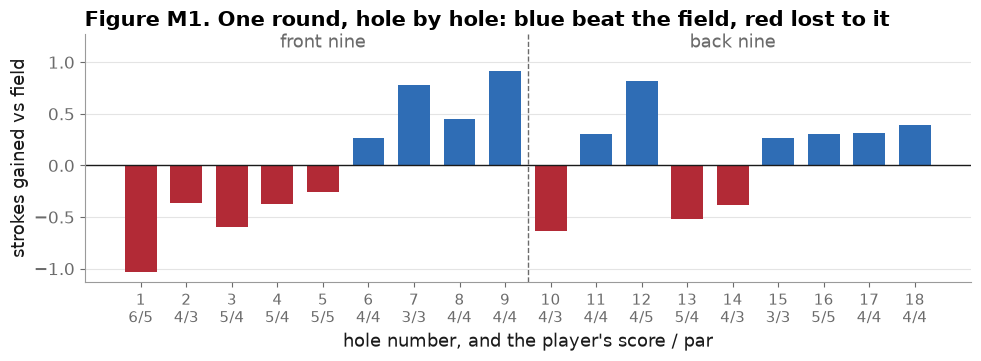

round SG +0.65 = sum of the 18 hole SGs; pairs used: 1-2 ... 8-9 and 10-11 ... 17-18


In [7]:
# ---- Figure M1: what hole-level strokes gained looks like for one round ----
# A round chosen at random (fixed seed) from players near the middle of the sample, for illustration only.
rr = np.random.default_rng(7)
mid = np.flatnonzero(np.abs(SG.sum(1)) < 2)
i = rr.choice(mid)
row = PRIMARY["mask_rows"][i]
sg_i = SG[i]

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(1, 19)
ax.bar(x, sg_i, color=np.where(sg_i >= 0, BLUE, RED), width=0.7)
ax.axhline(0, color=INK, lw=1)
ax.axvline(9.5, color=MUTED, lw=1, ls="--")
ax.set_xticks(x)
ax.set_xticklabels([f"{h}\n{s}/{p}" for h, s, p in zip(x, SCORE_ALL[row], PAR_ALL[row])], fontsize=10.5)
ax.set_xlabel("hole number, and the player's score / par")
ax.set_ylabel("strokes gained vs field")
ax.set_title("Figure M1. One round, hole by hole: blue beat the field, red lost to it")
ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 1.25)
ax.text(5, ax.get_ylim()[1] * 0.9, "front nine", ha="center", color=MUTED)
ax.text(14, ax.get_ylim()[1] * 0.9, "back nine", ha="center", color=MUTED)
ax.grid(axis="x", visible=False)
plt.tight_layout(); save(fig, "M1_example_round"); plt.show()
print(f"round SG {sg_i.sum():+.2f} = sum of the 18 hole SGs; pairs used: 1-2 ... 8-9 and 10-11 ... 17-18")

## 4. Analysis & Results  *(poster box: Analysis & Results)*

### 4a. Three layers of carry-over (Figure R1)

The same lag-1 correlation, computed four ways on the same pairs:

| row | what is removed |
|---|---|
| raw SG | nothing (hole difficulty only, via the field) |
| minus season mean | player skill |
| season z-score | player skill and streakiness (the abstract's controlled measure) |
| **shuffled within nine** | everything above, **plus** any hole-to-hole order. This is the day-form-only baseline |

In [8]:
# observed lag-1 r and player-bootstrap CIs for the three measures
layers = {}
for name, M in [("raw strokes gained", SG), ("minus season mean (skill)", D), ("season z-score (skill + volatility)", Z)]:
    s = lag_sums(M, 1)
    layers[name] = {"r": corr_from(s.sum(0)), "boot": boot_corr(s, W, PIDX)}

# permutation null: lag profile and bin means under shuffled hole order
NULL_PROFILE = np.array([lag_profile(shuffle_within_nines(Z, rng)) for _ in range(N_PERM)])
OBS_PROFILE  = lag_profile(Z)
null_r1 = NULL_PROFILE[:, 0]

momentum = OBS_PROFILE[0] - null_r1.mean()
mom_boot = layers["season z-score (skill + volatility)"]["boot"] - null_r1.mean()
p_perm = (1 + (null_r1 >= OBS_PROFILE[0]).sum()) / (1 + N_PERM)

HEADLINE = pd.DataFrame(
    [{"measure": k, "lag-1 r": v["r"], "95% CI low": ci(v["boot"])[0], "95% CI high": ci(v["boot"])[1]} for k, v in layers.items()]
    + [{"measure": "shuffled within nine (day form only)", "lag-1 r": null_r1.mean(),
        "95% CI low": ci(null_r1)[0], "95% CI high": ci(null_r1)[1]},
       {"measure": "MOMENTUM = z-score minus shuffled", "lag-1 r": momentum,
        "95% CI low": ci(mom_boot)[0], "95% CI high": ci(mom_boot)[1]}]
).set_index("measure")
print(HEADLINE.round(4).to_string())
print(f"\npermutation p-value (observed lag-1 r above every shuffle?): p = {p_perm:.4f}  ({N_PERM} shuffles)")
print(f"share of the skill-controlled carry-over that is day form: {null_r1.mean() / OBS_PROFILE[0]:.0%}")

check("the shuffled null removes the hole-to-hole sequence but not the day: its r is still positive", null_r1.mean() > 0)
check("raw > skill-controlled > 0", layers["raw strokes gained"]["r"] > layers["season z-score (skill + volatility)"]["r"] > 0)

                                      lag-1 r  95% CI low  95% CI high
measure                                                               
raw strokes gained                     0.0871      0.0830       0.0913
minus season mean (skill)              0.0422      0.0400       0.0441
season z-score (skill + volatility)    0.0392      0.0372       0.0410
shuffled within nine (day form only)   0.0356      0.0342       0.0370
MOMENTUM = z-score minus shuffled      0.0035      0.0015       0.0054

permutation p-value (observed lag-1 r above every shuffle?): p = 0.0020  (500 shuffles)
share of the skill-controlled carry-over that is day form: 91%
[PASS] the shuffled null removes the hole-to-hole sequence but not the day: its r is still positive
[PASS] raw > skill-controlled > 0


saved poster/figures/R1_carryover_layers.png and .pdf


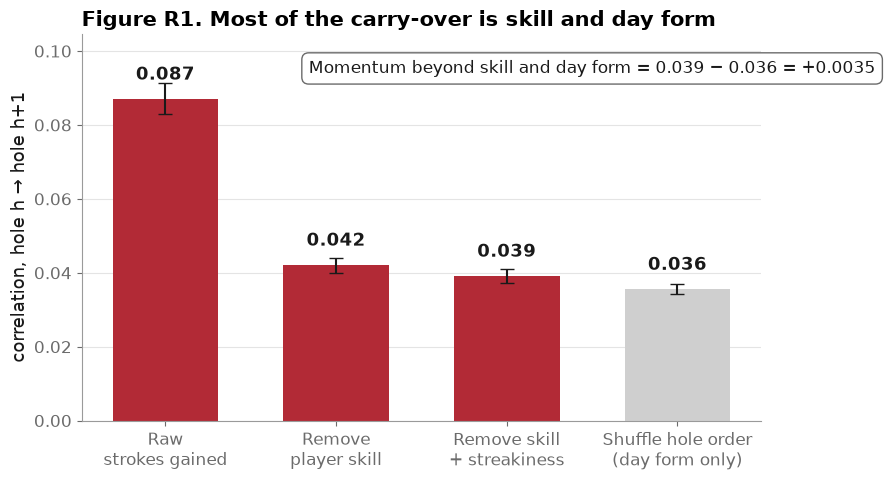

In [9]:
# ---- Figure R1: the carry-over shrinks as each explanation is removed ----
labels = ["Raw\nstrokes gained", "Remove\nplayer skill", "Remove skill\n+ streakiness", "Shuffle hole order\n(day form only)"]
vals = [layers[k]["r"] for k in layers] + [null_r1.mean()]
lo = [ci(layers[k]["boot"])[0] for k in layers] + [ci(null_r1)[0]]
hi = [ci(layers[k]["boot"])[1] for k in layers] + [ci(null_r1)[1]]

fig, ax = plt.subplots(figsize=(9, 5))
colors = [RED, RED, RED, NULL_FILL]
xs = np.arange(4)
ax.bar(xs, vals, color=colors, width=0.62)
ax.errorbar(xs, vals, yerr=[np.subtract(vals, lo), np.subtract(hi, vals)], fmt="none", ecolor=INK, capsize=5, lw=1.5)
for xi, v in zip(xs, vals):
    ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=13, color=INK, fontweight="bold")
ax.text(2.5, max(vals) * 1.08,
        f"Momentum beyond skill and day form = {OBS_PROFILE[0]:.3f} − {null_r1.mean():.3f} = +{momentum:.4f}",
        ha="center", fontsize=12.5, color=INK,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=MUTED))
ax.set_xticks(xs); ax.set_xticklabels(labels)
ax.set_ylabel("correlation, hole h → hole h+1")
ax.set_ylim(0, max(vals) * 1.2)
ax.set_title("Figure R1. Most of the carry-over is skill and day form")
ax.grid(axis="x", visible=False)
plt.tight_layout(); save(fig, "R1_carryover_layers"); plt.show()

### 4b. The lag profile (Figure R2): a spike at lag 1 is momentum, a flat line is day form

Correlation of z between two holes in the same nine, by how many holes apart they are. Day form
lifts every lag equally; momentum lifts lag 1 most. The grey band is the same profile with hole
order shuffled (95% of shuffles).

lag : observed r  [95% CI]   shuffled mean
  1 : 0.0392  [0.0372, 0.0410]   0.0356
  2 : 0.0372  [0.0353, 0.0391]   0.0356
  3 : 0.0350  [0.0331, 0.0371]   0.0356
  4 : 0.0328  [0.0307, 0.0349]   0.0356
  5 : 0.0340  [0.0315, 0.0363]   0.0356
  6 : 0.0343  [0.0315, 0.0371]   0.0358
  7 : 0.0301  [0.0263, 0.0335]   0.0357
  8 : 0.0354  [0.0309, 0.0402]   0.0355

lag-1 spike over lags 3-8: +0.0056  95% CI [0.0035 0.0075]


saved poster/figures/R2_lag_profile.png and .pdf


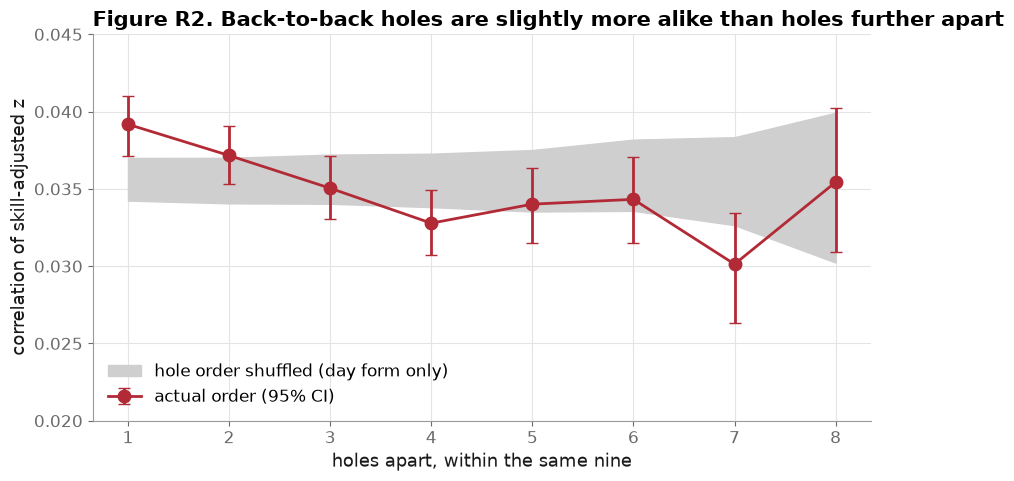

[PASS] lag-1 correlation is the largest of the profile


In [10]:
lags = np.arange(1, MAX_LAG + 1)
prof_boot = np.stack([boot_corr(lag_sums(Z, L), W, PIDX) for L in lags], 1)
far = OBS_PROFILE[2:].mean()                                   # lags 3..8
spike = OBS_PROFILE[0] - far
spike_boot = prof_boot[:, 0] - prof_boot[:, 2:].mean(1)
print("lag : observed r  [95% CI]   shuffled mean")
for L, o, (l, h), nm in zip(lags, OBS_PROFILE, np.percentile(prof_boot, [2.5, 97.5], axis=0).T, NULL_PROFILE.mean(0)):
    print(f"{L:3d} : {o:.4f}  [{l:.4f}, {h:.4f}]   {nm:.4f}")
print(f"\nlag-1 spike over lags 3-8: {spike:+.4f}  95% CI {np.round(ci(spike_boot), 4)}")

fig, ax = plt.subplots(figsize=(9, 5))
band = np.percentile(NULL_PROFILE, [2.5, 97.5], axis=0)
ax.fill_between(lags, band[0], band[1], color=NULL_FILL, label="hole order shuffled (day form only)")
cil = np.percentile(prof_boot, [2.5, 97.5], axis=0)
ax.errorbar(lags, OBS_PROFILE, yerr=[OBS_PROFILE - cil[0], cil[1] - OBS_PROFILE], color=RED, marker="o", ms=9,
            capsize=4, lw=2, label="actual order (95% CI)")
ax.set_xticks(lags)
ax.set_xlabel("holes apart, within the same nine")
ax.set_ylabel("correlation of skill-adjusted z")
ax.set_ylim(0.02, 0.045)   # zoomed: the differences are small; note the axis does not start at 0
ax.set_title("Figure R2. Back-to-back holes are slightly more alike than holes further apart")
ax.legend(loc="lower left")
plt.tight_layout(); save(fig, "R2_lag_profile"); plt.show()

check("lag-1 correlation is the largest of the profile", OBS_PROFILE[0] == OBS_PROFILE.max())

### 4c. Hot hand or cold hand? (Figure R3)

Split the current hole by how good it was (in the player's own SDs) and compare the next hole's
z with what the shuffle predicts. The shuffle accounts for day form, so the gap is the
sequential part only. Below zero means the next hole is worse than day form alone predicts.

  this-hole z  pairs  next-hole z (actual)  next-hole z (shuffled)  momentum (actual − shuffled)  95% CI low  95% CI high
         ≤ −2  58151               -0.1027                 -0.0821                       -0.0206     -0.0297      -0.0108
     −2 to −1 161017               -0.0617                 -0.0568                       -0.0049     -0.0100       0.0003
   −1 to −0.5 202138               -0.0308                 -0.0286                       -0.0022     -0.0066       0.0023
about average 623196               -0.0067                 -0.0090                        0.0023      0.0002       0.0044
     0.5 to 1 279531                0.0425                  0.0403                        0.0022     -0.0016       0.0059
       1 to 2 172887                0.0505                  0.0478                        0.0027     -0.0021       0.0077
          ≥ 2  17816                0.0889                  0.0948                       -0.0059     -0.0210       0.0106
saved poster/figures/R3_

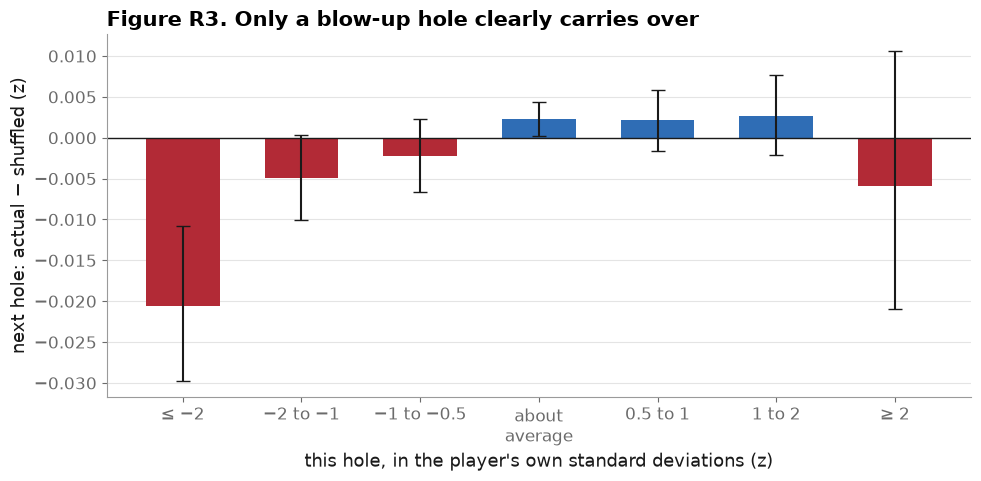

In [11]:
EDGES  = np.array([-np.inf, -2, -1, -0.5, 0.5, 1, 2, np.inf])
BIN_LABELS = ["≤ −2", "−2 to −1", "−1 to −0.5", "about\naverage", "0.5 to 1", "1 to 2", "≥ 2"]
nb = len(BIN_LABELS)

def bin_sums(M):
    "Per-round count and sum of next-hole z, by bin of this-hole z (lag-1 within-nine pairs)."
    a, b = M[:, PAIRS[1][:, 0]], M[:, PAIRS[1][:, 1]]
    k = np.digitize(a, EDGES[1:-1])
    cnt, tot = np.zeros((len(M), nb)), np.zeros((len(M), nb))
    rows = np.repeat(np.arange(len(M)), a.shape[1])
    np.add.at(cnt, (rows, k.ravel()), 1)
    np.add.at(tot, (rows, k.ravel()), b.ravel())
    return cnt, tot

cnt, tot = bin_sums(Z)
obs_bins = tot.sum(0) / cnt.sum(0)
null_bins = np.array([(lambda c, t: t.sum(0) / c.sum(0))(*bin_sums(shuffle_within_nines(Z, rng))) for _ in range(200)])
Pc, Pt = np.zeros((W.shape[1], nb)), np.zeros((W.shape[1], nb))
np.add.at(Pc, PIDX, cnt); np.add.at(Pt, PIDX, tot)
boot_bins = (W @ Pt) / (W @ Pc)
excess, excess_boot = obs_bins - null_bins.mean(0), boot_bins - null_bins.mean(0)
exl, exh = np.percentile(excess_boot, [2.5, 97.5], axis=0)

HOTCOLD = pd.DataFrame({"this-hole z": [l.replace("\n", " ") for l in BIN_LABELS], "pairs": cnt.sum(0).astype(int),
                        "next-hole z (actual)": obs_bins, "next-hole z (shuffled)": null_bins.mean(0),
                        "momentum (actual − shuffled)": excess, "95% CI low": exl, "95% CI high": exh})
print(HOTCOLD.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
xs = np.arange(nb)
ax.bar(xs, excess, color=np.where(excess >= 0, BLUE, RED), width=0.62)
ax.errorbar(xs, excess, yerr=[excess - exl, exh - excess], fmt="none", ecolor=INK, capsize=5, lw=1.5)
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(xs); ax.set_xticklabels(BIN_LABELS)
ax.set_xlabel("this hole, in the player's own standard deviations (z)")
ax.set_ylabel("next hole: actual − shuffled (z)")
ax.set_title("Figure R3. Only a blow-up hole clearly carries over")
ax.grid(axis="x", visible=False)
plt.tight_layout(); save(fig, "R3_hot_vs_cold"); plt.show()

cold, hot = HOTCOLD.iloc[0], HOTCOLD.iloc[-1]

### 4d. What a blow-up hole costs, in strokes

The correlations are in standardised units. To put the cold hand in strokes: after a hole where
the player lost 2 or more strokes to the field, how much do they lose on the next hole compared
with a shuffled order of the same round?

In [12]:
a_sg, b_sg = SG[:, PAIRS[1][:, 0]], SG[:, PAIRS[1][:, 1]]
blow = a_sg <= -2
obs_next = b_sg[blow].mean()
null_next = []
for _ in range(200):
    Sh = shuffle_within_nines(SG, rng)
    aa, bb = Sh[:, PAIRS[1][:, 0]], Sh[:, PAIRS[1][:, 1]]
    null_next.append(bb[aa <= -2].mean())
null_next = np.array(null_next)
STROKES_AFTER_BLOWUP = obs_next - null_next.mean()
print(f"holes losing 2+ strokes to the field: {blow.sum():,} ({blow.mean():.1%} of pairs)")
print(f"next hole SG after a blow-up: actual {obs_next:+.3f}, shuffled order {null_next.mean():+.3f}")
print(f"=> extra strokes lost on the next hole beyond day form: {STROKES_AFTER_BLOWUP:+.3f}"
      f"  (shuffles alone vary by {np.round(ci(null_next) - null_next.mean(), 3)})")

holes losing 2+ strokes to the field: 34,207 (2.3% of pairs)
next hole SG after a blow-up: actual -0.263, shuffled order -0.240
=> extra strokes lost on the next hole beyond day form: -0.023  (shuffles alone vary by [-0.009  0.009])


### 4e. Sensitivity: does the answer depend on choices made above?

Each row re-runs the whole pipeline (baseline, z, shuffle null) under one change. Momentum is the
lag-1 r minus the shuffled lag-1 r.

In [13]:
def momentum_for(mask, min_other=MIN_OTHER_ROUNDS, n_perm=100, n_boot=300):
    b = build(mask, min_other)
    Zs = b["Z"]
    s = lag_sums(Zs, 1)
    r1 = corr_from(s.sum(0))
    nl = np.array([corr_from(lag_sums(shuffle_within_nines(Zs, rng), 1).sum(0)) for _ in range(n_perm)])
    Wb, ib = player_weights(b["R"]["player_id"].to_numpy(), n_boot, rng)
    mb = boot_corr(s, Wb, ib) - nl.mean()
    return {"rounds": len(Zs), "players": b["R"]["player_id"].nunique(), "lag-1 r": r1, "shuffled r": nl.mean(),
            "momentum": r1 - nl.mean(), "95% CI low": ci(mb)[0], "95% CI high": ci(mb)[1]}

variants = {
    "PRIMARY": (scope_mask(), MIN_OTHER_ROUNDS),
    "dual / match events included": (scope_mask(exclude_match=False), MIN_OTHER_ROUNDS),
    "large fields only (30+ players)": (scope_mask(min_field=30), MIN_OTHER_ROUNDS),
    "stricter baseline (6+ other rounds)": (scope_mask(), 6),
}
for s in sorted(R_ALL["season_label"].astype(str).unique()):
    variants[f"season {s} only"] = (scope_mask(season=s), MIN_OTHER_ROUNDS)
variants["WOMEN (same pipeline)"] = (scope_mask(gender="Women"), MIN_OTHER_ROUNDS)

print(f"extreme rounds (median hole +5) left in the primary sample: {int(R['is_extreme_round'].sum())} "
      "(they fall out with the small-field and baseline filters, so no separate check is needed)\n")
SENSITIVITY = pd.DataFrame({k: momentum_for(m, mo) for k, (m, mo) in variants.items()}).T
SENSITIVITY[["rounds", "players"]] = SENSITIVITY[["rounds", "players"]].astype(int)
print(SENSITIVITY.round(4).to_string())

men = SENSITIVITY.drop(index="WOMEN (same pipeline)")
check("momentum is positive in every men's variant", (men["momentum"] > 0).all())
n_sig = int((men["95% CI low"] > 0).sum())
print(f"CI excludes zero in {n_sig} of {len(men)} men's variants")

extreme rounds (median hole +5) left in the primary sample: 0 (they fall out with the small-field and baseline filters, so no separate check is needed)



                                     rounds  players  lag-1 r  shuffled r  momentum  95% CI low  95% CI high
PRIMARY                               94671     4662   0.0392      0.0356    0.0035      0.0017       0.0055
dual / match events included          96455     4720   0.0399      0.0361    0.0038      0.0019       0.0056
large fields only (30+ players)       85302     4385   0.0372      0.0339    0.0033      0.0014       0.0051
stricter baseline (6+ other rounds)   85998     3688   0.0379      0.0344    0.0036      0.0016       0.0055
season 2023-24 only                   26784     2337   0.0382      0.0362    0.0020     -0.0018       0.0055
season 2024-25 only                   32495     2604   0.0411      0.0368    0.0043      0.0013       0.0073
season 2025-26 only                   35392     2689   0.0381      0.0339    0.0042      0.0012       0.0073
WOMEN (same pipeline)                 54926     2713   0.0883      0.0859    0.0023     -0.0008       0.0057
[PASS] momentum is 

In [14]:
# ---- POSTER TEXT: Results box (numbers from this run) ----
H = HEADLINE["lag-1 r"]
print("POSTER TEXT -----------------------------------------------------------------")
print(f"""• Raw carry-over: beating the field on one hole predicts beating it on the next
  (r = {H.iloc[0]:.3f}, 95% CI {HEADLINE.iloc[0, 1]:.3f}–{HEADLINE.iloc[0, 2]:.3f}).
• Skill explains more than half of it: against each player's own season baseline,
  r = {H.iloc[2]:.3f} ({HEADLINE.iloc[2, 1]:.3f}–{HEADLINE.iloc[2, 2]:.3f}).
• Most of what is left is day form: with hole order shuffled inside each nine, r is still
  {H.iloc[3]:.3f}. A good day makes every hole better, not just the next one.
• Momentum beyond skill and day form is small but real: +{momentum:.4f} in r
  (95% CI {HEADLINE.iloc[4, 1]:+.4f} to {HEADLINE.iloc[4, 2]:+.4f}; permutation p = {p_perm:.3f}).
  Back-to-back holes are more alike than holes further apart (Figure R2).
• The clearest piece is a cold hand: after a blow-up hole (z ≤ −2) the next hole is {abs(cold['momentum (actual − shuffled)']):.3f} SD
  worse than day form predicts (CI {cold['95% CI low']:+.3f} to {cold['95% CI high']:+.3f}), about {abs(STROKES_AFTER_BLOWUP):.2f} strokes. After a great
  hole (z ≥ 2) there is no detectable extra boost ({hot['momentum (actual − shuffled)']:+.3f} SD, CI {hot['95% CI low']:+.3f} to {hot['95% CI high']:+.3f}).
• Momentum is positive in all {len(men)} men's sensitivity checks ({men['momentum'].min():+.4f} to {men['momentum'].max():+.4f}),
  with a CI above zero in {n_sig} of {len(men)}.""")

POSTER TEXT -----------------------------------------------------------------
• Raw carry-over: beating the field on one hole predicts beating it on the next
  (r = 0.087, 95% CI 0.083–0.091).
• Skill explains more than half of it: against each player's own season baseline,
  r = 0.039 (0.037–0.041).
• Most of what is left is day form: with hole order shuffled inside each nine, r is still
  0.036. A good day makes every hole better, not just the next one.
• Momentum beyond skill and day form is small but real: +0.0035 in r
  (95% CI +0.0015 to +0.0054; permutation p = 0.002).
  Back-to-back holes are more alike than holes further apart (Figure R2).
• The clearest piece is a cold hand: after a blow-up hole (z ≤ −2) the next hole is 0.021 SD
  worse than day form predicts (CI -0.030 to -0.011), about 0.02 strokes. After a great
  hole (z ≥ 2) there is no detectable extra boost (-0.006 SD, CI -0.021 to +0.011).
• Momentum is positive in all 7 men's sensitivity checks (+0.0020 to +0.0043),

## 5. Conclusion  *(poster box: Conclusion)*

In [15]:
print("POSTER TEXT -----------------------------------------------------------------")
print(f"""Hole-to-hole carry-over in college golf is mostly not momentum. About
{1 - H.iloc[2] / H.iloc[0]:.0%} of the raw correlation is player skill, and about {null_r1.mean() / OBS_PROFILE[0]:.0%} of what remains is
day form: players have good and bad days, not good and bad holes. A small sequential
effect does survive both controls, and it runs mainly in one direction: a blow-up hole is
followed by a worse-than-expected next hole, the same direction as the cold hand Elmore &
Urbaczewski found on the PGA Tour. The effect is real but tiny, about {abs(STROKES_AFTER_BLOWUP):.2f} strokes on the
hole after a blow-up. The hot hand golfers feel is mostly a hot *day*.""")

POSTER TEXT -----------------------------------------------------------------
Hole-to-hole carry-over in college golf is mostly not momentum. About
55% of the raw correlation is player skill, and about 91% of what remains is
day form: players have good and bad days, not good and bad holes. A small sequential
effect does survive both controls, and it runs mainly in one direction: a blow-up hole is
followed by a worse-than-expected next hole, the same direction as the cold hand Elmore &
Urbaczewski found on the PGA Tour. The effect is real but tiny, about 0.02 strokes on the
hole after a blow-up. The hot hand golfers feel is mostly a hot *day*.


## 6. Future work  *(poster box: Future)*

**POSTER TEXT (draft).**

- **Order of play.** Tee times or starting holes would let us use all 17 transitions and rule
  out shotgun-start misordering.
- **Shot level.** Clippd shot data could show *where* a cold hand comes from: tee shots, approach
  or putting.
- **Replicate the PGA study.** A birdie/bogey mixed model with a player-round random effect
  (`02_momentum_analysis.ipynb`) is the direct comparison with Elmore & Urbaczewski.
- **Women and Divisions I/II.** Same pipeline; compare effect sizes across levels.
- **Recovery.** Does a team's coaching (or a player's routine) shorten the cold hand?

## 7. Sources  *(poster box: Sources)*

1. Gilovich, T., Vallone, R., & Tversky, A. (1985). The hot hand in basketball: On the misperception of random sequences. *Cognitive Psychology*, 17(3), 295–314.
2. Miller, J. B., & Sanjurjo, A. (2018). Surprised by the hot hand fallacy? A truth in the law of small numbers. *Econometrica*, 86(6), 2019–2047.
3. Elmore, R., & Urbaczewski, A. (2018). Hot and cold hands on the PGA Tour: Do they exist? SSRN 2764498.
4. Broadie, M. (2012). Assessing golfer performance on the PGA TOUR. *Interfaces*, 42(2), 146–165. *(strokes gained)*
5. Data: Clippd, NCAA Division III golf, 2023-24 to 2025-26.

## 8. Abstract (revised, numbers from this run)

Changes from the original abstract, and why:

| original | problem | revised |
|---|---|---|
| "play-by-play data" | the data are hole scores, not shots | "hole-by-hole scores" |
| "near-identical conditions" | consecutive holes differ in par and length | "no defender or opponent", with difficulty handled by the field |
| "standardizing … against their own season-long baseline" removes the confound | it removes skill but not **day form**, which is most of what remains | adds the shuffled-order test |
| "a positive carry-over persists" | true, but most of it is day form | reports momentum net of day form, and that it is mainly a cold hand |
| "unlike in professional play" | Elmore & Urbaczewski found a significant **cold** hand on the PGA Tour; Arkes (2016) and Livingston (2012) report pro hot hands | compares the result with the PGA cold hand |

In [16]:
print("ABSTRACT ---------------------------------------------------------------------")
print(f"""The "hot hand" (whether recent success predicts continued success) has been debated since
Gilovich, Vallone, and Tversky (1985) found no evidence of it in basketball shooting. Golf
offers a cleaner test: there is no defender or opponent, and every player in a field faces the
same holes on the same day. Using {DATA_AT_A_GLANCE['holes']} hole-by-hole scores from NCAA Division III men's
tournaments ({DATA_AT_A_GLANCE['seasons']}), we measure strokes gained on each hole against a leave-one-out
average of the rest of the field on that course and day, and ask whether strokes gained on one
hole predicts strokes gained on the next. Raw carry-over is clear (r = {H.iloc[0]:.2f}), but much of it is
skill: standardizing each player against their own season baseline cuts it to r = {H.iloc[2]:.3f}. Shuffling
the order of holes within each nine shows that most of the remainder is day form (r = {H.iloc[3]:.3f}).
A small sequential effect survives both controls (+{momentum:.3f}, 95% CI {HEADLINE.iloc[4, 1]:.3f} to {HEADLINE.iloc[4, 2]:.3f}), and it is
mainly a cold hand: after a blow-up hole, players lose about {abs(STROKES_AFTER_BLOWUP):.2f} extra strokes on the next
hole beyond what their day predicts, with no matching boost after a great hole. This matches
the direction of the cold hand reported on the PGA Tour. In college golf, what looks like a hot
hand is mostly a hot day.""")

ABSTRACT ---------------------------------------------------------------------
The "hot hand" (whether recent success predicts continued success) has been debated since
Gilovich, Vallone, and Tversky (1985) found no evidence of it in basketball shooting. Golf
offers a cleaner test: there is no defender or opponent, and every player in a field faces the
same holes on the same day. Using 1,704,078 hole-by-hole scores from NCAA Division III men's
tournaments (2023-24 to 2025-26), we measure strokes gained on each hole against a leave-one-out
average of the rest of the field on that course and day, and ask whether strokes gained on one
hole predicts strokes gained on the next. Raw carry-over is clear (r = 0.09), but much of it is
skill: standardizing each player against their own season baseline cuts it to r = 0.039. Shuffling
the order of holes within each nine shows that most of the remainder is day form (r = 0.036).
A small sequential effect survives both controls (+0.004, 95% CI 0.002 

In [17]:
tests = pd.DataFrame(TESTS)
print(f"{int(tests['passed'].sum())} of {len(tests)} tests passed.")
print("figures:", ", ".join(sorted(p.name for p in FIG_DIR.glob("*.png"))))

12 of 12 tests passed.
figures: M1_example_round.png, R1_carryover_layers.png, R2_lag_profile.png, R3_hot_vs_cold.png
